# 02. TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU TUYỂN DỤNG IT
**Dự án:** Phân tích Dữ liệu Tuyển dụng IT Việt Nam (IT Recruitment Analysis)  
**Mục tiêu Notebook:**
1. Khảo sát cấu trúc và chất lượng 4 tệp dữ liệu thô (`ITViec_data.csv`, `TopCV_jobs.csv`, `job_descriptions.csv`, `vietjobs_sample.csv`).
2. Khử trùng lặp bản ghi hoàn toàn và loại bỏ các tin tuyển dụng ngoài ngành (phi IT).
3. Chuẩn hóa mức lương về đơn vị thống nhất (Triệu VNĐ/tháng), tách min/max/avg và nhận diện tin thỏa thuận.
4. Chuẩn hóa Tỉnh/Thành phố làm việc đồng nhất giữa các nguồn.
5. Chuẩn hóa và phân nhóm vị trí IT (`role_category`).
6. Trích xuất số năm kinh nghiệm (`exp_years_min`) và suy luận cấp bậc (`job_level`).
7. Chuẩn hóa danh sách kỹ năng công nghệ (`skills_list`) và bù khuyết từ tiêu đề.
8. Hợp nhất đa nguồn, khử trùng lặp logic liên nguồn và xuất dữ liệu sạch vào `data/processed/it_jobs_cleaned.csv`.
9. Ghi nhận nhật ký xử lý vào `reports/cleaning_log.xlsx` và từ điển dữ liệu vào `reports/data_dictionary.xlsx`.


In [1]:
# Khai báo các thư viện cần thiết
import os
import re
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập cấu hình hiển thị và đồ họa
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid")

# Định nghĩa các đường dẫn thư mục
RAW_DIR = r"../data/raw"
INTERIM_DIR = r"../data/interim"
PROCESSED_DIR = r"../data/processed"
REPORTS_DIR = r"../reports"

os.makedirs(INTERIM_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(os.path.join(REPORTS_DIR, "data_quality"), exist_ok=True)

print("Đã tải các thư viện và cấu hình môi trường thành công!")


Đã tải các thư viện và cấu hình môi trường thành công!


## 1. Khảo sát và Đọc dữ liệu thô ban đầu
Đọc 4 tập dữ liệu thu thập được từ các nền tảng:
- **ITViec_data.csv:** Dữ liệu việc làm CNTT chuyên sâu từ ITViec.
- **TopCV_jobs.csv:** Dữ liệu việc làm CNTT từ nền tảng TopCV.
- **job_descriptions.csv:** Bộ dữ liệu mô tả công việc IT tổng hợp từ đa nền tảng.
- **vietjobs_sample.csv:** Tập tin mẫu thử nghiệm.


In [2]:
# Đọc 4 tệp dữ liệu thô
df_itv_raw = pd.read_csv(os.path.join(RAW_DIR, "ITViec_data.csv"))
df_top_raw = pd.read_csv(os.path.join(RAW_DIR, "TopCV_jobs.csv"))
df_jd_raw = pd.read_csv(os.path.join(RAW_DIR, "job_descriptions.csv"))
df_vj_raw = pd.read_csv(os.path.join(RAW_DIR, "vietjobs_sample.csv"))

print(f"1. ITViec Raw:           {df_itv_raw.shape[0]:>5} dòng, {df_itv_raw.shape[1]} cột")
print(f"2. TopCV Raw:            {df_top_raw.shape[0]:>5} dòng, {df_top_raw.shape[1]} cột")
print(f"3. Job Descriptions Raw: {df_jd_raw.shape[0]:>5} dòng, {df_jd_raw.shape[1]} cột")
print(f"4. VietJobs Sample Raw:  {df_vj_raw.shape[0]:>5} dòng, {df_vj_raw.shape[1]} cột")
print("-" * 55)
print(f"Tổng số bản ghi ban đầu: {len(df_itv_raw) + len(df_top_raw) + len(df_jd_raw) + len(df_vj_raw)} dòng")


1. ITViec Raw:            1159 dòng, 10 cột
2. TopCV Raw:              616 dòng, 7 cột
3. Job Descriptions Raw:  3101 dòng, 11 cột
4. VietJobs Sample Raw:      5 dòng, 18 cột
-------------------------------------------------------
Tổng số bản ghi ban đầu: 4881 dòng


## 2. Khử trùng lặp hoàn toàn và Loại bỏ tin ngoài ngành (Phi IT)
### Vấn đề:
- `TopCV_jobs.csv` chứa 42 dòng trùng lặp 100%.
- `ITViec_data.csv` chứa 15 dòng trùng lặp 100%.
- `TopCV_jobs.csv` có 27 dòng là công việc cơ khí, máy phay/tiện CNC, kỹ thuật điện dân dụng do từ khóa cào dữ liệu "lập trình" bị nhầm lẫn.
- `vietjobs_sample.csv` toàn bộ là công việc ngoài ngành (xử lý nước thải, đánh giá ISO, phát triển thị trường).


In [3]:
cleaning_logs = []

def log_action(step, dataset, before, after, dropped, desc, rule):
    cleaning_logs.append({
        "Bước thực hiện": step,
        "Tập dữ liệu": dataset,
        "Số lượng trước": before,
        "Số lượng sau": after,
        "Bản ghi loại bỏ": dropped,
        "Nội dung biến đổi": desc,
        "Quy tắc / Phương pháp áp dụng": rule
    })

NON_IT_KEYWORDS = [
    "cnc", "nx cam", "vận hành máy", "kỹ thuật điện", "xử lý nước", 
    "iso 22000", "haccp", "vietgap", "thị trường", "cơ khí", 
    "sửa chữa điện", "phay cnc", "tiện cnc", "bảo trì hệ thống xử lý"
]

def is_it_job(title):
    t_lower = str(title).lower()
    for kw in NON_IT_KEYWORDS:
        if kw in t_lower:
            return False
    return True

# 1. ITViec
df_itv = df_itv_raw.drop_duplicates().copy()
log_action("Khử trùng lặp hoàn toàn", "ITViec_data.csv", len(df_itv_raw), len(df_itv), 
           len(df_itv_raw) - len(df_itv), "Xóa bản ghi trùng lặp 100%", "drop_duplicates()")

mask_itv = df_itv['job_names'].apply(is_it_job)
df_itv = df_itv[mask_itv].copy()
log_action("Lọc công việc phi IT", "ITViec_data.csv", len(mask_itv), len(df_itv),
           len(mask_itv) - len(df_itv), "Loại bỏ tin cơ khí/ngoài ngành", "Bộ lọc từ khóa ngành IT")

# 2. TopCV
df_top = df_top_raw.drop_duplicates().copy()
log_action("Khử trùng lặp hoàn toàn", "TopCV_jobs.csv", len(df_top_raw), len(df_top),
           len(df_top_raw) - len(df_top), "Xóa bản ghi trùng lặp 100%", "drop_duplicates()")

mask_top = df_top['title'].apply(is_it_job)
df_top = df_top[mask_top].copy()
log_action("Lọc công việc phi IT", "TopCV_jobs.csv", len(mask_top), len(df_top),
           len(mask_top) - len(df_top), "Loại bỏ 27 tin lập trình CNC, máy phay, kỹ thuật điện", "Bộ lọc từ khóa phi IT")

# 3. Job Descriptions
df_jd = df_jd_raw.drop_duplicates().copy()
log_action("Khử trùng lặp hoàn toàn", "job_descriptions.csv", len(df_jd_raw), len(df_jd),
           len(df_jd_raw) - len(df_jd), "Kiểm tra trùng lặp bản ghi", "drop_duplicates()")

# 4. VietJobs Sample
mask_vj = df_vj_raw['job_title'].apply(is_it_job)
df_vj = df_vj_raw[mask_vj].copy()
log_action("Lọc công việc phi IT", "vietjobs_sample.csv", len(df_vj_raw), len(df_vj),
           len(df_vj_raw) - len(df_vj), "Loại bỏ 100% công việc phi IT trong sample", "Bộ lọc từ khóa IT")

print("Kết quả sau bước 2:")
print(f"- ITViec:           {len(df_itv)} dòng (loại {len(df_itv_raw) - len(df_itv)} dòng)")
print(f"- TopCV:            {len(df_top)} dòng (loại {len(df_top_raw) - len(df_top)} dòng)")
print(f"- Job Descriptions: {len(df_jd)} dòng (loại {len(df_jd_raw) - len(df_jd)} dòng)")
print(f"- VietJobs Sample:  {len(df_vj)} dòng (loại {len(df_vj_raw) - len(df_vj)} dòng)")


Kết quả sau bước 2:
- ITViec:           1144 dòng (loại 15 dòng)
- TopCV:            547 dòng (loại 69 dòng)
- Job Descriptions: 3101 dòng (loại 0 dòng)
- VietJobs Sample:  1 dòng (loại 4 dòng)


## 3. Chuẩn hóa Mức lương (Salary Normalization)
Quy đổi thống nhất về đơn vị **Triệu VNĐ/tháng**, trích xuất `salary_min`, `salary_max`, `salary_avg`, và gán `is_negotiable = True` cho tin thỏa thuận.


In [4]:
USD_TO_VND_MILLION = 25.4 / 1000  # 1 USD = 0.0254 triệu VNĐ

def parse_salary(val):
    if pd.isna(val):
        return None, None, None, True
    
    val_str = str(val).strip()
    val_lower = val_str.lower()
    
    negotiable_keywords = [
        "love it", "negotiable", "attractive", "thương lượng", "thoả thuận", 
        "thỏa thuận", "competitive", "discuss", "nego", "hấp dẫn", "tùy năng lực",
        "month salary", "acttractive"
    ]
    if any(k in val_lower for k in negotiable_keywords):
        return None, None, None, True
    
    year_match = re.search(r'\$?(\d+)\s*k?\s*(?:/year|per year)', val_lower)
    if year_match:
        usd_year = float(year_match.group(1)) * 1000
        vnd_monthly = (usd_year * USD_TO_VND_MILLION) / 12
        return round(vnd_monthly, 1), round(vnd_monthly, 1), round(vnd_monthly, 1), False

    is_usd = bool(re.search(r'\$|usd', val_lower))
    
    cleaned = re.sub(r'(\d),(\d)', r'\1\2', val_str)
    cleaned = re.sub(r'(\d+)\.(\d{3})\.(\d{3})', r'\1\2\3', cleaned)
    cleaned = re.sub(r'(\d+)\.(\d{3})', r'\1\2', cleaned)
    
    vnd_full_match = re.findall(r'(\d{7,9})', cleaned)
    if vnd_full_match and not is_usd:
        nums = [float(x) / 1_000_000 for x in vnd_full_match]
        if len(nums) == 1:
            if any(k in val_lower for k in ["tới", "up to", "dưới"]):
                return None, round(nums[0], 1), round(nums[0], 1), False
            return round(nums[0], 1), None, round(nums[0], 1), False
        elif len(nums) >= 2:
            return round(nums[0], 1), round(nums[1], 1), round((nums[0] + nums[1])/2, 1), False

    range_match = re.search(r'(\d+(?:\.\d+)?)\s*(?:tr|m|triệu|k|\$)?\s*(?:-|–|to)\s*(\d+(?:\.\d+)?)', cleaned)
    if range_match:
        n1 = float(range_match.group(1))
        n2 = float(range_match.group(2))
        if is_usd:
            v1 = n1 * 25.4 if n1 < 100 else n1 * USD_TO_VND_MILLION
            v2 = n2 * 25.4 if n2 < 100 else n2 * USD_TO_VND_MILLION
            return round(v1, 1), round(v2, 1), round((v1 + v2)/2, 1), False
        else:
            return round(n1, 1), round(n2, 1), round((n1 + n2)/2, 1), False
            
    upto_match = re.search(r'(?:up to|upto|tới|dưới|<|nhỏ hơn)\s*\$?(\d+(?:\.\d+)?)', cleaned, re.IGNORECASE)
    if upto_match:
        n = float(upto_match.group(1))
        v = (n * 25.4 if n < 100 else n * USD_TO_VND_MILLION) if is_usd else n
        return None, round(v, 1), round(v, 1), False
        
    from_match = re.search(r'(?:from|từ|trên|lớn hơn|>)\s*\$?(\d+(?:\.\d+)?)', cleaned, re.IGNORECASE)
    if from_match:
        n = float(from_match.group(1))
        v = (n * 25.4 if n < 100 else n * USD_TO_VND_MILLION) if is_usd else n
        return round(v, 1), None, round(v, 1), False
        
    return None, None, None, True

sal_itv = [parse_salary(s) for s in df_itv['salaries']]
df_itv['salary_min'] = [s[0] for s in sal_itv]
df_itv['salary_max'] = [s[1] for s in sal_itv]
df_itv['salary_avg'] = [s[2] for s in sal_itv]
df_itv['is_negotiable'] = [s[3] for s in sal_itv]

sal_top = [parse_salary(s) for s in df_top['salary']]
df_top['salary_min'] = [s[0] for s in sal_top]
df_top['salary_max'] = [s[1] for s in sal_top]
df_top['salary_avg'] = [s[2] for s in sal_top]
df_top['is_negotiable'] = [s[3] for s in sal_top]

df_jd['salary_min'] = np.nan
df_jd['salary_max'] = np.nan
df_jd['salary_avg'] = np.nan
df_jd['is_negotiable'] = True

sal_known_itv = df_itv[~df_itv['is_negotiable']]['salary_avg']
sal_known_top = df_top[~df_top['is_negotiable']]['salary_avg']
print("Thống kê mức lương sau chuẩn hóa (Triệu VNĐ/tháng):")
print(f"- ITViec công khai lương: {len(sal_known_itv)}/{len(df_itv)} ({len(sal_known_itv)/len(df_itv)*100:.1f}%), Trung bình: {sal_known_itv.mean():.1f} triệu VNĐ")
print(f"- TopCV công khai lương:  {len(sal_known_top)}/{len(df_top)} ({len(sal_known_top)/len(df_top)*100:.1f}%), Trung bình: {sal_known_top.mean():.1f} triệu VNĐ")


Thống kê mức lương sau chuẩn hóa (Triệu VNĐ/tháng):
- ITViec công khai lương: 345/1144 (30.2%), Trung bình: 44.8 triệu VNĐ
- TopCV công khai lương:  292/547 (53.4%), Trung bình: 32.4 triệu VNĐ


## 4. Chuẩn hóa Tỉnh / Thành phố làm việc (Location Standardization)
Chuẩn hóa các định dạng địa chỉ tự do về các trung tâm tuyển dụng IT chính.


In [5]:
def standardize_city(val):
    if not val or pd.isna(val):
        return "Không xác định"
    s = str(val).lower()
    
    if "not specified" in s or "chưa xác định" in s:
        return "Không xác định"
    if "remote" in s or "toàn quốc" in s:
        return "Remote / Toàn quốc"
    if any(k in s for k in ["hồ chí minh", "ho chi minh", "hcm", "sài gòn", "sai gon", "thu duc", "thủ đức", "qtsc"]):
        return "Hồ Chí Minh"
    if any(k in s for k in ["hà nội", "ha noi", "cau giay", "cầu giấy", "ba đình", "ba dinh", "đống đa", "dong da", "hai bà trưng", "hai ba trung"]):
        return "Hà Nội"
    if "đà nẵng" in s or "da nang" in s:
        return "Đà Nẵng"
    if "cần thơ" in s or "can tho" in s:
        return "Cần Thơ"
    if "hải phòng" in s or "hai phong" in s:
        return "Hải Phòng"
    if "bình dương" in s or "binh duong" in s:
        return "Bình Dương"
    if "bắc ninh" in s or "bac ninh" in s:
        return "Bắc Ninh"
    if "đồng nai" in s or "dong nai" in s:
        return "Đồng Nai"
    return "Khác"

df_itv['city'] = df_itv['locate_names'].apply(standardize_city)
df_top['city'] = df_top['location'].apply(standardize_city)
df_jd['city'] = df_jd['city'].apply(standardize_city)

print("Phân bố Thành phố trong tập dữ liệu ITViec:")
print(df_itv['city'].value_counts())


Phân bố Thành phố trong tập dữ liệu ITViec:


city
Hồ Chí Minh           713
Hà Nội                385
Đà Nẵng                30
Remote / Toàn quốc      8
Khác                    6
Cần Thơ                 1
Bình Dương              1
Name: count, dtype: int64


## 5. Chuẩn hóa Phân loại Chuyên môn IT (Role Classification)
Phân loại về 12 danh mục chuẩn: Backend, Frontend, Fullstack, Mobile, QA/QC, DevOps/Cloud, Data/AI, BA/PM, Security, Embedded, Software Engineer chung, và Khác.


In [6]:
def classify_role(title, original_role=None):
    combined = f"{str(original_role)} {str(title)}".lower()
    
    if any(k in combined for k in ["fullstack", "full-stack", "full stack"]):
        return "Fullstack Developer"
    if any(k in combined for k in ["mobile", "ios", "android", "flutter", "react native", "swift", "kotlin"]):
        return "Mobile Developer"
    if any(k in combined for k in ["frontend", "front-end", "front end", "reactjs", "react js", "vue", "angular"]):
        return "Frontend Developer"
    if any(k in combined for k in ["backend", "back-end", "back end", "java", "python", "golang", "go dev", "php", ".net", "nodejs", "node.js"]):
        return "Backend Developer"
    if any(k in combined for k in ["qa", "qc", "tester", "testing", "test", "quality assurance", "kiem thu", "kiểm thử"]):
        return "QA / QC / Tester"
    if any(k in combined for k in ["devops", "cloud", "sre", "system", "sysadmin", "infrastructure", "ha tang", "hạ tầng"]):
        return "DevOps / Cloud / System"
    if any(k in combined for k in ["data engineer", "data analyst", "data scientist", "ai", "machine learning", "deep learning", "nlp", "llm", "bi analyst", "du lieu", "dữ liệu"]):
        return "Data / AI / Machine Learning"
    if any(k in combined for k in ["security", "an toan thong tin", "an toàn thông tin", "bao mat", "bảo mật", "cyber", "pentest"]):
        return "Security / Network"
    if any(k in combined for k in ["business analyst", "ba ", "po ", "product owner", "project manager", "pm ", "scrum master"]):
        return "BA / PM / Product"
    if any(k in combined for k in ["embedded", "iot", "nhung", "nhúng", "firmware", "hardware", "vi mach", "vi mạch"]):
        return "Embedded / IoT"
    if any(k in combined for k in ["software engineer", "lap trinh vien", "lập trình viên", "developer", "engineer"]):
        return "Software Engineer (Chung)"
    return "Other IT Roles"

df_itv['role_category'] = [classify_role(t, p) for t, p in zip(df_itv['job_names'], df_itv['position_names'])]
df_top['role_category'] = [classify_role(t) for t in df_top['title']]
df_jd['role_category'] = [classify_role(t, r) for t, r in zip(df_jd['title'], df_jd['it_role_type'])]

print("Top vai trò IT được tuyển dụng nhiều nhất (TopCV):")
print(df_top['role_category'].value_counts())


Top vai trò IT được tuyển dụng nhiều nhất (TopCV):
role_category
Backend Developer               126
Other IT Roles                   80
Data / AI / Machine Learning     58
Software Engineer (Chung)        56
Fullstack Developer              54
Mobile Developer                 50
DevOps / Cloud / System          48
Frontend Developer               41
QA / QC / Tester                 17
Embedded / IoT                   13
Security / Network                2
BA / PM / Product                 2
Name: count, dtype: int64


## 6. Chuẩn hóa Kinh nghiệm & Cấp bậc Nghề nghiệp (Level & Experience)
Trích xuất số năm kinh nghiệm tối thiểu (`exp_years_min`) và suy luận cấp bậc chuyên môn (`job_level`).


In [7]:
def extract_experience_and_level(title, exp_text=None, level_text=None):
    combined = f"{str(title)} {str(exp_text)} {str(level_text)}".lower()
    
    years = None
    m = re.search(r'(?:từ|at least|tối thiểu|minimum|từ)?\s*(\d+)(?:\+|\s*-\s*\d+)?\s*(?:năm|year|years)', combined)
    if m:
        try:
            years = float(m.group(1))
        except:
            years = None

    if any(k in combined for k in ["intern", "thực tập", "fresher", "trainee"]):
        level = "Intern / Fresher"
        if years is None:
            years = 0.0
    elif any(k in combined for k in ["lead", "trưởng nhóm", "manager", "quản lý", "director", "architect", "giám đốc", "head"]):
        level = "Lead / Manager"
    elif any(k in combined for k in ["senior", "sr.", "chuyên gia"]):
        level = "Senior"
    elif any(k in combined for k in ["junior", "jr."]):
        level = "Junior"
    elif any(k in combined for k in ["middle", "mid-level", "mid level"]):
        level = "Middle"
    elif years is not None:
        if years < 1:
            level = "Intern / Fresher"
        elif years < 2:
            level = "Junior"
        elif years < 4:
            level = "Middle"
        elif years < 7:
            level = "Senior"
        else:
            level = "Lead / Manager"
    else:
        level = "Không xác định"
        
    return years, level

exp_itv = [extract_experience_and_level(t, e) for t, e in zip(df_itv['job_names'], df_itv['exp_skills'])]
df_itv['exp_years_min'] = [e[0] for e in exp_itv]
df_itv['job_level'] = [e[1] for e in exp_itv]

exp_top = [extract_experience_and_level(t, level_text=l) for t, l in zip(df_top['title'], df_top['level'])]
df_top['exp_years_min'] = [e[0] for e in exp_top]
df_top['job_level'] = [e[1] for e in exp_top]

exp_jd = [extract_experience_and_level(t, exp_text=d) for t, d in zip(df_jd['title'], df_jd['description'])]
df_jd['exp_years_min'] = [e[0] for e in exp_jd]
df_jd['job_level'] = [e[1] for e in exp_jd]

print("Phân bố cấp bậc tuyển dụng (Toàn bộ dữ liệu ITViec):")
print(df_itv['job_level'].value_counts())


Phân bố cấp bậc tuyển dụng (Toàn bộ dữ liệu ITViec):
job_level
Lead / Manager      505
Senior              212
Middle              181
Intern / Fresher    110
Không xác định       86
Junior               50
Name: count, dtype: int64


## 7. Chuẩn hóa & Bù khuyết Kỹ năng Công nghệ (Skills Parsing & Imputation)
Chuẩn hóa danh sách kỹ năng công nghệ và quét bù khuyết cho các bản ghi bị thiếu từ tiêu đề tuyển dụng.


In [8]:
TECH_KEYWORDS = [
    "Python", "Java", "C++", "C#", ".NET", "ASP.NET", "JavaScript", "TypeScript", 
    "React", "ReactJS", "Vue", "VueJS", "Angular", "NodeJS", "Node.js", "PHP", 
    "Golang", "Go", "Swift", "Kotlin", "Flutter", "React Native", "SQL", "MySQL", 
    "PostgreSQL", "MongoDB", "Redis", "Oracle", "Docker", "Kubernetes", "K8s", 
    "AWS", "Azure", "GCP", "CI/CD", "Git", "Linux", "Spring Boot", "Spring", 
    "Django", "FastAPI", "Flask", "Laravel", "Kafka", "Spark", "TensorFlow", 
    "PyTorch", "HTML", "CSS", "Tailwind", "Bootstrap", "Selenium", "Cypress", 
    "JMeter", "Postman", "GraphQL", "REST API", "Microservices", "Hadoop", "Tableau", "Power BI"
]

def parse_and_impute_skills(skills_val, text_fallback=""):
    extracted = set()
    if pd.notna(skills_val):
        s_val = str(skills_val).strip()
        if s_val.startswith("[") and s_val.endswith("]"):
            try:
                parsed = ast.literal_eval(s_val)
                if isinstance(parsed, list):
                    for item in parsed:
                        item_clean = str(item).strip()
                        if item_clean:
                            extracted.add(item_clean)
            except:
                pass
        
        if not extracted:
            parts = re.split(r'[,;|\n]+', s_val)
            for p in parts:
                p_clean = p.strip()
                if p_clean and len(p_clean) < 30:
                    words = p_clean.split()
                    if len(words) > 1 and all(w in TECH_KEYWORDS or len(w) <= 12 for w in words):
                        for w in words:
                            extracted.add(w)
                    else:
                        extracted.add(p_clean)

    if not extracted and text_fallback:
        t_clean = str(text_fallback)
        for kw in TECH_KEYWORDS:
            pattern = r'\b' + re.escape(kw) + r'\b'
            if re.search(pattern, t_clean, re.IGNORECASE):
                extracted.add(kw)

    return ", ".join(sorted(list(extracted)))

df_itv['skills_list'] = [parse_and_impute_skills(sk, t) for sk, t in zip(df_itv['array_skills'], df_itv['job_names'])]
df_top['skills_list'] = [parse_and_impute_skills(sk, t) for sk, t in zip(df_top['skills'], df_top['title'])]
df_jd['skills_list'] = [parse_and_impute_skills(f"{str(l)} {str(k)}", t) for l, k, t in zip(df_jd['main_programming_languages'], df_jd['key_technologies'], df_jd['title'])]

print("Mẫu danh sách kỹ năng sau chuẩn hóa:")
for s in df_itv['skills_list'].head(5):
    print("-", s)


Mẫu danh sách kỹ năng sau chuẩn hóa:
- API, Database, Java, Oracle, PL/SQL, Spring Boot
- AI, Automation Test, MLOps, QA QC, Tester
- AI, Computer Vision, Deep Learning, LLM, Machine Learning, Python
- API, Figma, Mockups, NodeJS, Python, UI-UX
- Cloud, DevOps


## 8. Hợp nhất Đa nguồn & Khử trùng lặp logic Liên nguồn (Data Integration)
Hợp nhất về lược đồ chuẩn hóa duy nhất và khử trùng lặp theo `(company, job_title, city)`.


In [9]:
# Bổ sung thông tin nguồn và ngày đăng tin
df_itv['source'] = "ITViec"
df_itv['post_date'] = pd.to_datetime(df_itv['post_dates_formatted'], format='%d/%m/%Y %H:%M', errors='coerce').dt.strftime('%Y-%m-%d')

df_top['source'] = "TopCV"
df_top['post_date'] = np.nan

df_jd['source'] = df_jd['site'].fillna("JobDescriptions")
df_jd['post_date'] = np.nan

# Lưu các tệp interim
df_itv.to_csv(os.path.join(INTERIM_DIR, "ITViec_cleaned.csv"), index=False, encoding='utf-8-sig')
df_top.to_csv(os.path.join(INTERIM_DIR, "TopCV_cleaned.csv"), index=False, encoding='utf-8-sig')
df_jd.to_csv(os.path.join(INTERIM_DIR, "job_descriptions_cleaned.csv"), index=False, encoding='utf-8-sig')

COMMON_COLUMNS = [
    'job_title', 'company', 'city', 'role_category', 'job_level', 'exp_years_min',
    'salary_min', 'salary_max', 'salary_avg', 'is_negotiable', 'skills_list', 'source', 'post_date'
]

cols_itv = {'job_names': 'job_title', 'company_names': 'company'}
cols_top = {'title': 'job_title'}
cols_jd = {'title': 'job_title'}

df_itv_sub = df_itv.rename(columns=cols_itv)[COMMON_COLUMNS]
df_top_sub = df_top.rename(columns=cols_top)[COMMON_COLUMNS]
df_jd_sub = df_jd.rename(columns=cols_jd)[COMMON_COLUMNS]

df_merged = pd.concat([df_itv_sub, df_top_sub, df_jd_sub], ignore_index=True)
n_before_cross = len(df_merged)

df_merged['clean_company'] = df_merged['company'].astype(str).str.lower().str.strip()
df_merged['clean_title'] = df_merged['job_title'].astype(str).str.lower().str.strip()

# Ưu tiên bản ghi có lương
df_merged = df_merged.sort_values(by=['is_negotiable'], ascending=True)
df_final = df_merged.drop_duplicates(subset=['clean_company', 'clean_title', 'city']).copy()
df_final = df_final.drop(columns=['clean_company', 'clean_title'])

log_action("Khử trùng lặp logic đa nguồn", "Dataset Hợp nhất", n_before_cross, len(df_final),
           n_before_cross - len(df_final), "Khử trùng lặp theo cặp (company, title, city), ưu tiên giữ bản ghi có lương",
           "drop_duplicates(subset=[company, title, city])")

final_csv_path = os.path.join(PROCESSED_DIR, "it_jobs_cleaned.csv")
df_final.to_csv(final_csv_path, index=False, encoding='utf-8-sig')

print(f"Tổng số bản ghi ban đầu:            {len(df_itv_raw) + len(df_top_raw) + len(df_jd_raw) + len(df_vj_raw)} dòng")
print(f"Tổng số bản ghi sau khi làm sạch:  {len(df_final)} dòng")
print(f"Đã lưu kết quả thành công tại: {final_csv_path}")


Tổng số bản ghi ban đầu:            4881 dòng


Tổng số bản ghi sau khi làm sạch:  4207 dòng
Đã lưu kết quả thành công tại: ../data/processed\it_jobs_cleaned.csv


## 9. Trực quan hóa Khám phá Dữ liệu Sau Làm Sạch (Quick Visualizations)
Vẽ 4 biểu đồ tổng quan chất lượng dữ liệu sau tiền xử lý.


C:\Users\ASUS\AppData\Local\Temp\ipykernel_36340\1767255607.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_counts.values, y=city_counts.index, ax=axes[0, 0], palette="Blues_r")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_36340\1767255607.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=role_counts.values, y=role_counts.index, ax=axes[0, 1], palette="Greens_r")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_36340\1767255607.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_salary, x='job_level', y='salary_avg', ax=axes

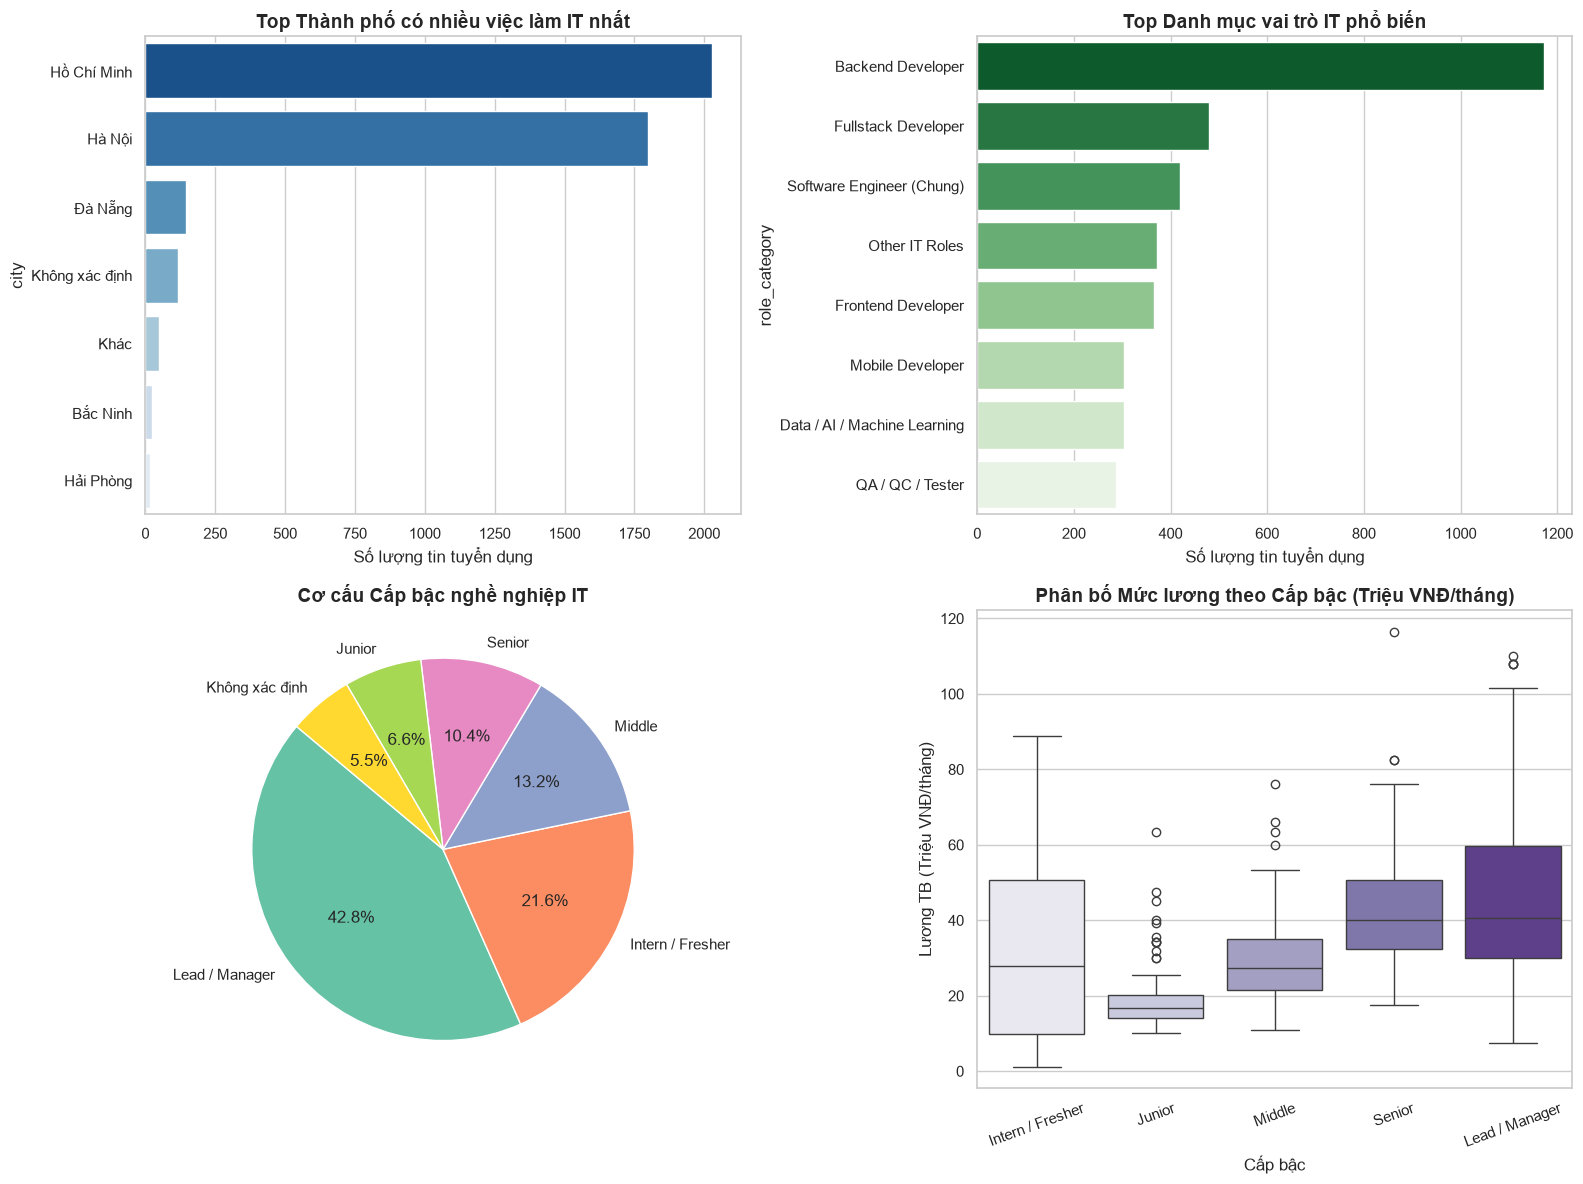

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Phân bố việc làm theo Thành phố
city_counts = df_final['city'].value_counts().head(7)
sns.barplot(x=city_counts.values, y=city_counts.index, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Top Thành phố có nhiều việc làm IT nhất", fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel("Số lượng tin tuyển dụng")

# 2. Phân bố các Nhóm vai trò IT
role_counts = df_final['role_category'].value_counts().head(8)
sns.barplot(x=role_counts.values, y=role_counts.index, ax=axes[0, 1], palette="Greens_r")
axes[0, 1].set_title("Top Danh mục vai trò IT phổ biến", fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel("Số lượng tin tuyển dụng")

# 3. Phân bố Cấp bậc nghề nghiệp
level_counts = df_final['job_level'].value_counts()
axes[1, 0].pie(level_counts.values, labels=level_counts.index, autopct='%1.1f%%', startangle=140,
               colors=sns.color_palette("Set2"))
axes[1, 0].set_title("Cơ cấu Cấp bậc nghề nghiệp IT", fontsize=14, fontweight='bold')

# 4. Phân bố Mức lương theo Cấp bậc (cho các tin công khai lương)
df_salary = df_final[~df_final['is_negotiable'] & df_final['salary_avg'].notna() & (df_final['salary_avg'] < 120)]
sns.boxplot(data=df_salary, x='job_level', y='salary_avg', ax=axes[1, 1], palette="Purples",
            order=["Intern / Fresher", "Junior", "Middle", "Senior", "Lead / Manager"])
axes[1, 1].set_title("Phân bố Mức lương theo Cấp bậc (Triệu VNĐ/tháng)", fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel("Cấp bậc")
axes[1, 1].set_ylabel("Lương TB (Triệu VNĐ/tháng)")
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
chart_path = os.path.join(REPORTS_DIR, "data_quality", "cleaning_overview.png")
plt.savefig(chart_path, dpi=300)
plt.show()


## 10. Xuất Báo cáo Nhật ký Làm sạch & Từ điển Dữ liệu
Cập nhật `reports/cleaning_log.xlsx` và `reports/data_dictionary.xlsx`.


In [11]:
df_log = pd.DataFrame(cleaning_logs)
log_path = os.path.join(REPORTS_DIR, "cleaning_log.xlsx")
with pd.ExcelWriter(log_path, engine='openpyxl') as writer:
    df_log.to_excel(writer, sheet_name="NhatKyLamSach", index=False)

dict_data = [
    {"Tên trường": "job_title", "Kiểu dữ liệu": "String", "Mô tả": "Tiêu đề vị trí tuyển dụng IT gốc", "Ví dụ": "Senior Java Backend Developer"},
    {"Tên trường": "company", "Kiểu dữ liệu": "String", "Mô tả": "Tên doanh nghiệp / nhà tuyển dụng", "Ví dụ": "FPT Software, Viettel"},
    {"Tên trường": "city", "Kiểu dữ liệu": "Category", "Mô tả": "Tỉnh/Thành phố chuẩn hóa", "Ví dụ": "Hà Nội, Hồ Chí Minh, Đà Nẵng"},
    {"Tên trường": "role_category", "Kiểu dữ liệu": "Category", "Mô tả": "Nhóm chuyên môn IT chuẩn hóa", "Ví dụ": "Backend Developer, Mobile Developer"},
    {"Tên trường": "job_level", "Kiểu dữ liệu": "Category", "Mô tả": "Cấp bậc vị trí tuyển dụng", "Ví dụ": "Intern / Fresher, Junior, Middle, Senior, Lead"},
    {"Tên trường": "exp_years_min", "Kiểu dữ liệu": "Float", "Mô tả": "Số năm kinh nghiệm tối thiểu", "Ví dụ": "2.0, 5.0"},
    {"Tên trường": "salary_min", "Kiểu dữ liệu": "Float", "Mô tả": "Lương tối thiểu (Triệu VNĐ/tháng)", "Ví dụ": "20.0, 25.4"},
    {"Tên trường": "salary_max", "Kiểu dữ liệu": "Float", "Mô tả": "Lương tối đa (Triệu VNĐ/tháng)", "Ví dụ": "35.0, 50.8"},
    {"Tên trường": "salary_avg", "Kiểu dữ liệu": "Float", "Mô tả": "Lương trung bình ước tính (Triệu VNĐ/tháng)", "Ví dụ": "27.5, 38.1"},
    {"Tên trường": "is_negotiable", "Kiểu dữ liệu": "Boolean", "Mô tả": "Mức lương dạng thỏa thuận/bảo mật", "Ví dụ": "True / False"},
    {"Tên trường": "skills_list", "Kiểu dữ liệu": "String", "Mô tả": "Danh sách kỹ năng/công nghệ phân tách bằng dấu phẩy", "Ví dụ": "Java, Spring Boot, SQL"},
    {"Tên trường": "source", "Kiểu dữ liệu": "String", "Mô tả": "Nguồn thu thập dữ liệu", "Ví dụ": "ITViec, TopCV, LinkedIn"},
    {"Tên trường": "post_date", "Kiểu dữ liệu": "Date (YYYY-MM-DD)", "Mô tả": "Ngày đăng tin tuyển dụng", "Ví dụ": "2025-11-25"}
]
df_dict = pd.DataFrame(dict_data)
dict_path = os.path.join(REPORTS_DIR, "data_dictionary.xlsx")
with pd.ExcelWriter(dict_path, engine='openpyxl') as writer:
    df_dict.to_excel(writer, sheet_name="TuDienDuLieu", index=False)

print("BẢNG TỔNG KẾT NHẬT KÝ LÀM SẠCH DỮ LIỆU:")
print(df_log.to_string())
print("\nHoàn tất toàn bộ quy trình tiền xử lý và làm sạch dữ liệu!")


BẢNG TỔNG KẾT NHẬT KÝ LÀM SẠCH DỮ LIỆU:
                 Bước thực hiện           Tập dữ liệu  Số lượng trước  Số lượng sau  Bản ghi loại bỏ                                                            Nội dung biến đổi                   Quy tắc / Phương pháp áp dụng
0       Khử trùng lặp hoàn toàn       ITViec_data.csv            1159          1144               15                                                   Xóa bản ghi trùng lặp 100%                               drop_duplicates()
1          Lọc công việc phi IT       ITViec_data.csv            1144          1144                0                                               Loại bỏ tin cơ khí/ngoài ngành                         Bộ lọc từ khóa ngành IT
2       Khử trùng lặp hoàn toàn        TopCV_jobs.csv             616           574               42                                                   Xóa bản ghi trùng lặp 100%                               drop_duplicates()
3          Lọc công việc phi IT        TopCV_jobs.csv   